# Week 9 · Topic 3 — Register and Login

**Mohammed Mohammed Alhaji** · CST1510 · 26 November 2026

**Box we are building: PROCESS, made safe, and usable**

Wiring bcrypt into a real, if simple, authentication flow against a file.

> **Already know this?** Skip to the *Topic 3 Challenge*.

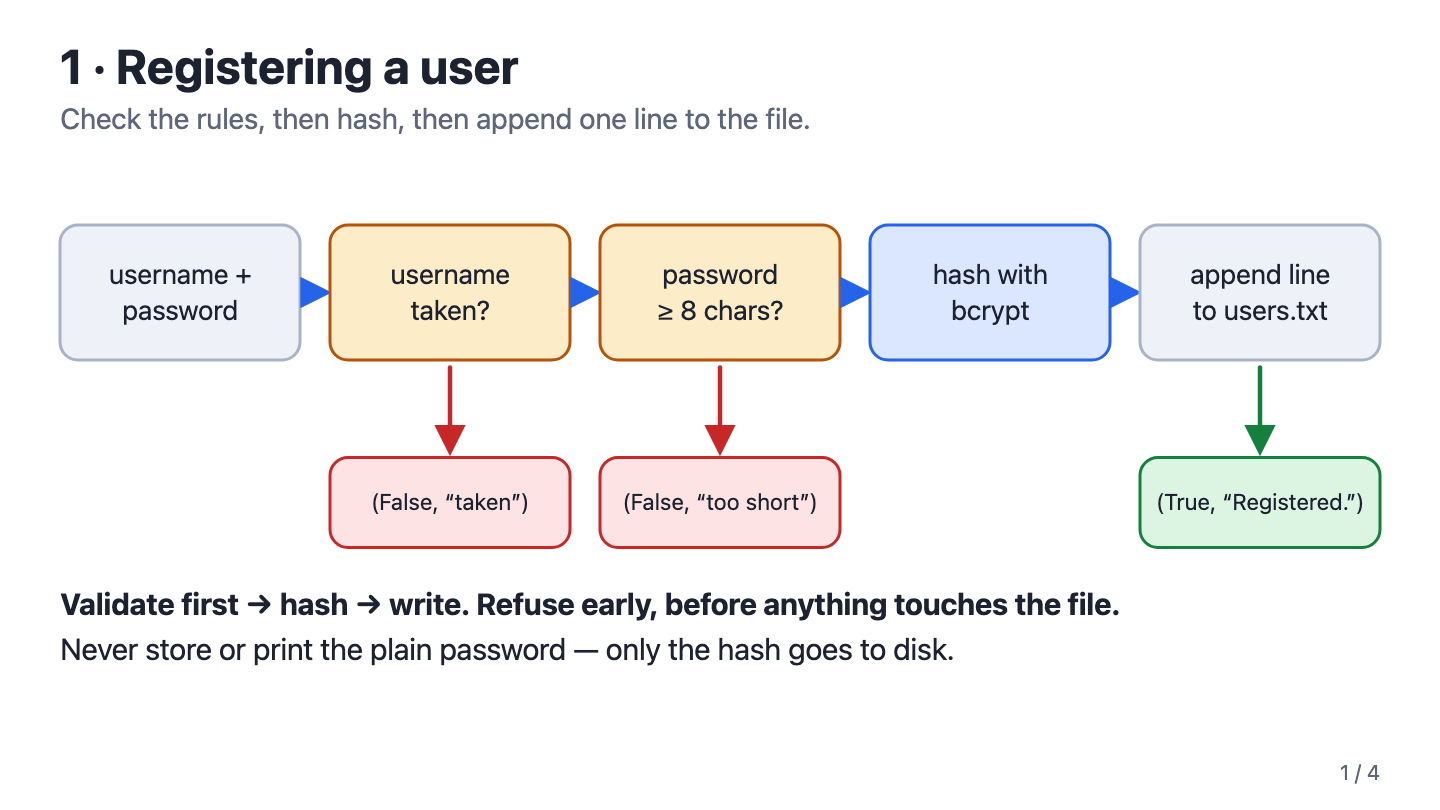

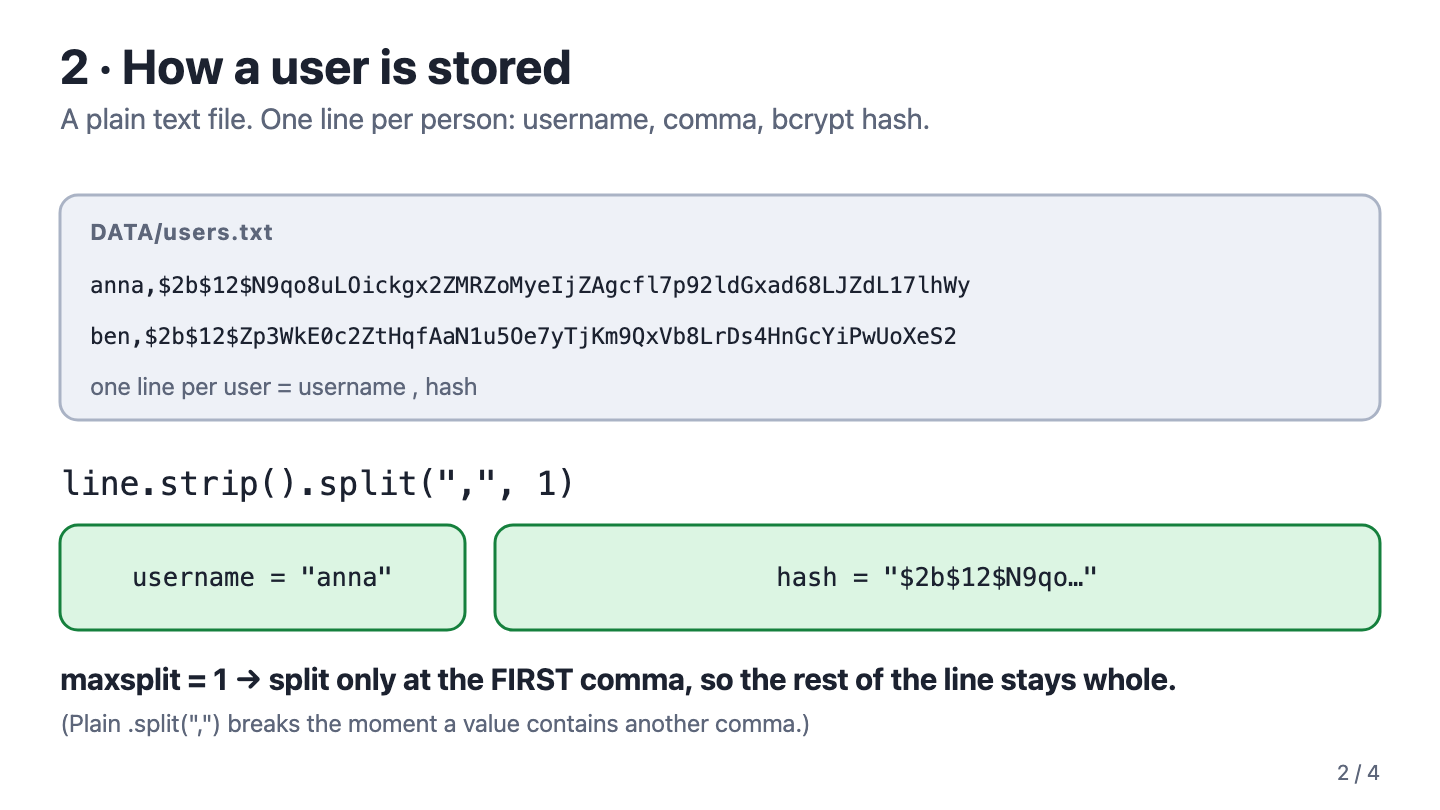

---
## 1. Registering — hash, then append

In [1]:
import bcrypt
from pathlib import Path
from tempfile import TemporaryDirectory

# These are classroom accounts in an isolated temporary folder.
demo_directory = TemporaryDirectory()
demo_file = Path(demo_directory.name) / "demo.txt"

def register_user(username, password, path=demo_file):
    """Hash password and append username,hash to the store."""
    hashed = bcrypt.hashpw(password.encode("utf-8"), bcrypt.gensalt())
    with open(path, "a", encoding="utf-8") as f:
        f.write(f"{username},{hashed.decode('utf-8')}\n")

register_user("alice", "correct-horse-battery-staple", demo_file)
with open(demo_file, encoding="utf-8") as f:
    print(f.read())

alice,$2b$12$xAjIYR7ntRVPo/JkBJon6.9nn.Ze/Hl0wrzgiWCOdnbESOH5W9ziq



### Your turn
Register a second user into the same file and print the file's contents.

In [2]:
register_user("bob", "classroom-bob-password", demo_file)
with open(demo_file, encoding="utf-8") as f:
    print(f.read())
# Both records contain bcrypt hashes of dummy classroom passwords.

alice,$2b$12$xAjIYR7ntRVPo/JkBJon6.9nn.Ze/Hl0wrzgiWCOdnbESOH5W9ziq
bob,$2b$12$rITTMwBVUmeJ0H6vVtQxXuE6yS6psiZee0N9c13hnYQyUeMtiylH6



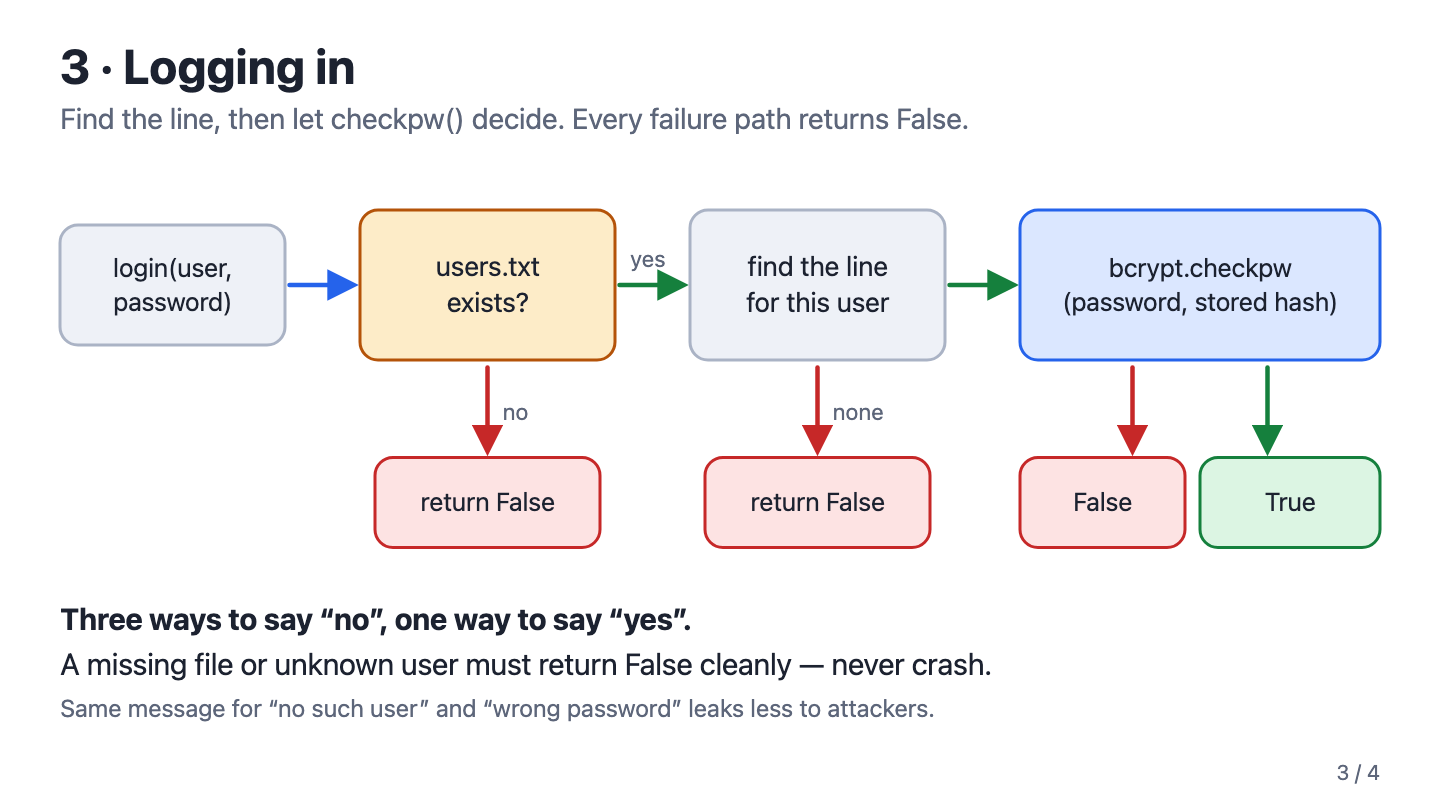

---
## 2. Logging in — find the line, then `checkpw()`

Week 7's `.strip().split(",", 1)` pattern, applied to a security-relevant
file.

In [3]:
def login_user(username, password, path=demo_file):
    """Return True if username/password match a stored, hashed record."""
    with open(path) as f:
        for line in f:
            stored_username, stored_hash = line.strip().split(",", 1)
            if stored_username == username:
                return bcrypt.checkpw(password.encode("utf-8"), stored_hash.encode("utf-8"))
    return False

print(login_user("alice", "correct-horse-battery-staple", demo_file))
print(login_user("alice", "wrong-guess", demo_file))

True


False


### Your turn
Log in with a username that was never registered, and confirm it returns `False` without crashing.

In [4]:
result = login_user("unregistered_user", "dummy-password", demo_file)
print(result)
assert result is False

False


---
## 3. A missing file should not crash a login attempt

The first person to ever try logging in will hit a file that does not exist
yet — handle it, do not let it crash.

In [5]:
import os

def login_user_safe(username, password, path=demo_file):
    """Return False, not a crash, if the store does not exist yet."""
    if not os.path.exists(path):
        return False
    return login_user(username, password, path)

print(login_user_safe("nobody", "anything", Path(demo_directory.name) / "does_not_exist.txt"))

False


### Your turn
Call `login_user_safe` on a path you know does not exist and confirm it returns `False` cleanly.

In [6]:
missing_file = Path(demo_directory.name) / "no_accounts_yet.txt"
print("File exists:", missing_file.exists())
result = login_user_safe("nobody", "dummy-password", missing_file)
print("Login accepted:", result)
assert result is False

File exists: False
Login accepted: False


---
## 4. Refusing a duplicate username

Registering the same username twice silently creates two records — the
`login()` function only ever finds the first. Worth refusing outright.

In [7]:
def username_exists(username, path=demo_file):
    """Return True if username already has a record in the store."""
    if not os.path.exists(path):
        return False
    with open(path, encoding="utf-8") as f:
        for line in f:
            stored_username, separator, stored_hash = line.strip().partition(",")
            if separator and stored_username == username:
                return True
    return False

### Your turn
Use `username_exists` inside `register_user` to refuse a duplicate registration, returning `False` instead of writing a second line.

In [8]:
def register_user(username, password, path=demo_file):
    """Register a new user and return False if the username is taken."""
    if username_exists(username, path):
        return False
    hashed = bcrypt.hashpw(password.encode("utf-8"), bcrypt.gensalt())
    with open(path, "a", encoding="utf-8") as f:
        f.write(f"{username},{hashed.decode('utf-8')}\n")
    return True

before = demo_file.read_text(encoding="utf-8")
print("Duplicate accepted:", register_user("alice", "another-dummy-password", demo_file))
print("File unchanged:", demo_file.read_text(encoding="utf-8") == before)
assert demo_file.read_text(encoding="utf-8") == before

Duplicate accepted: False
File unchanged: True


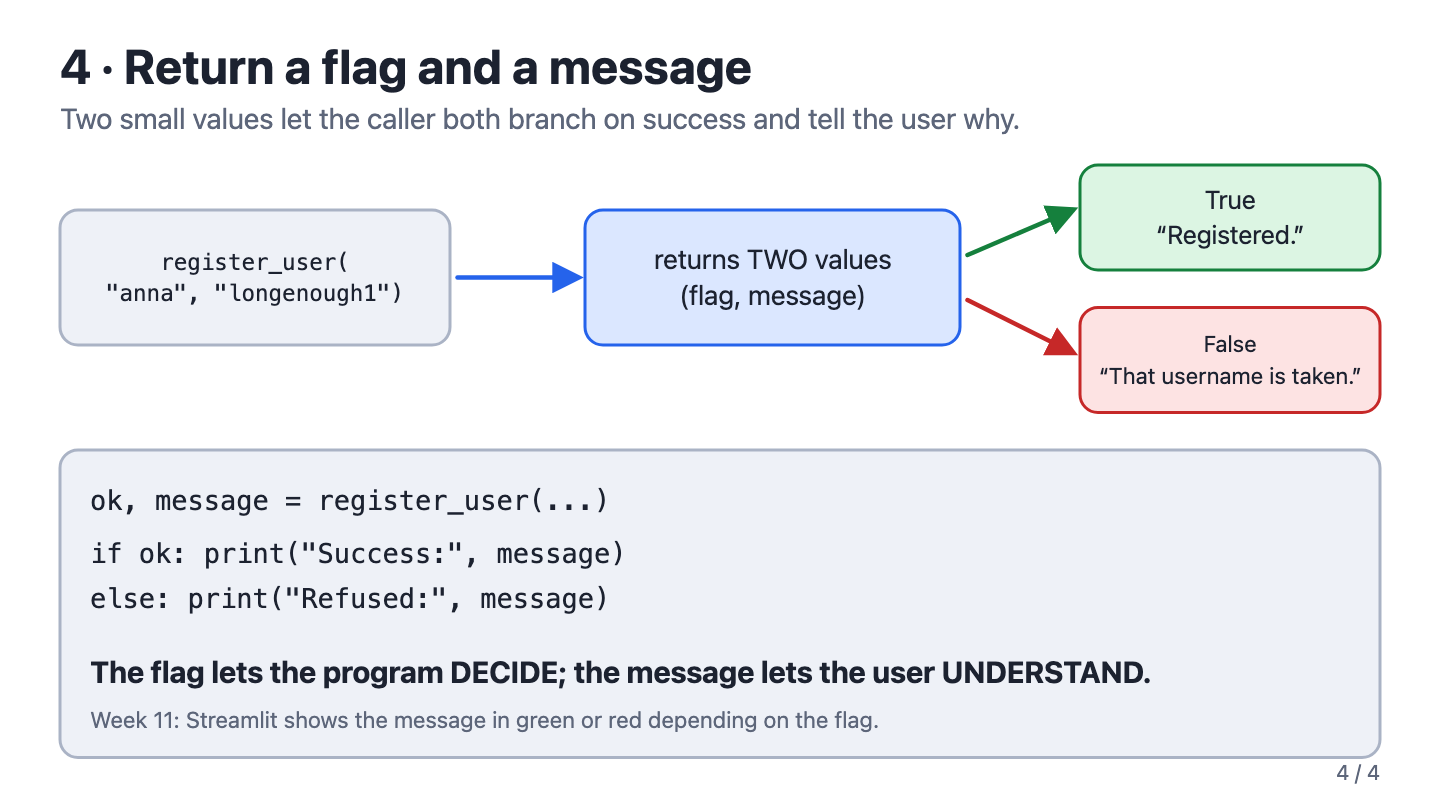

---
## 5. Return a flag and a message

The lab's functions return two values, `(True, "Registered.")` or `(False, "That username is already taken.")`. The program that
calls them can then both decide what to do (the flag) and show the user what happened (the message). In Week 11 the Streamlit page
prints the message in green or red depending on the flag.

```python
ok, message = register_user("anna", "longenough1")
if ok:
    print("Success:", message)
else:
    print("Refused:", message)
```

### Your turn
Change `register_user` so it refuses a password shorter than 8 characters, returning `(False, "Password must be at least 8 characters.")`.
Then call it with a short password and print the message.

In [9]:
def register_user(username, password, path=demo_file):
    """Register a new user and return a success flag and message."""
    if len(password) < 8:
        return False, "Password must be at least 8 characters."
    if username_exists(username, path):
        return False, "That username is already taken."
    hashed = bcrypt.hashpw(password.encode("utf-8"), bcrypt.gensalt())
    with open(path, "a", encoding="utf-8") as f:
        f.write(f"{username},{hashed.decode('utf-8')}\n")
    return True, "Registered."

ok, message = register_user("short_password_demo", "short", demo_file)
print(message)
assert ok is False
assert username_exists("short_password_demo", demo_file) is False

Password must be at least 8 characters.


---
## Topic 3 Challenge

Build a complete register/login pair — hashing, duplicate-username refusal,
and a missing-file-safe login — and test all three behaviours: a fresh
registration, a duplicate attempt, and a login with the wrong password.

In [10]:
def register_user(username, password, path):
    """Validate an account, refuse duplicates and store its bcrypt hash."""
    username = username.strip()
    if not username or any(character in username for character in ",\n\r"):
        return False, "Use a nonempty username without commas or line breaks."
    if len(password) < 8:
        return False, "Password must be at least 8 characters."
    password_bytes = password.encode("utf-8")
    if len(password_bytes) > 72:
        return False, "Password must be at most 72 UTF-8 bytes."
    if username_exists(username, path):
        return False, "That username is already taken."
    hashed = bcrypt.hashpw(password_bytes, bcrypt.gensalt())
    with open(path, "a", encoding="utf-8") as f:
        f.write(f"{username},{hashed.decode('utf-8')}\n")
    return True, "Registered."


def login_user(username, password, path):
    """Check a password, returning False for missing or malformed records."""
    username = username.strip()
    password_bytes = password.encode("utf-8")
    if len(password_bytes) > 72:
        return False
    try:
        with open(path, encoding="utf-8") as f:
            for line in f:
                stored_username, separator, stored_hash = line.strip().partition(",")
                if separator and stored_username == username:
                    try:
                        return bcrypt.checkpw(password_bytes, stored_hash.encode("utf-8"))
                    except ValueError:
                        return False
    except FileNotFoundError:
        return False
    return False


with TemporaryDirectory() as folder:
    accounts = Path(folder) / "users.txt"
    print("Missing-file login:", login_user("demo_user", "classroom-pass", accounts))

    ok, message = register_user("demo_user", "classroom-pass", accounts)
    print("Fresh registration:", ok, message)
    assert ok is True

    original = accounts.read_text(encoding="utf-8")
    ok, message = register_user("demo_user", "second-classroom-pass", accounts)
    print("Duplicate attempt:", ok, message)
    assert ok is False
    assert accounts.read_text(encoding="utf-8") == original

    correct = login_user("demo_user", "classroom-pass", accounts)
    wrong = login_user("demo_user", "wrong-classroom-pass", accounts)
    unknown = login_user("someone_else", "classroom-pass", accounts)
    print("Correct password:", correct)
    print("Wrong password:", wrong)
    print("Unknown username:", unknown)
    assert correct is True
    assert wrong is False
    assert unknown is False

    assert register_user("short_demo", "short", accounts)[0] is False
    assert register_user("invalid,name", "classroom-pass", accounts)[0] is False
    assert register_user("long_demo", "x" * 73, accounts)[0] is False
    assert len(accounts.read_text(encoding="utf-8").splitlines()) == 1
    stored_hash = accounts.read_text(encoding="utf-8").strip().split(",", 1)[1]
    assert bcrypt.checkpw(b"classroom-pass", stored_hash.encode("utf-8"))
    assert "classroom-pass" not in accounts.read_text(encoding="utf-8")
    print("Only one hashed account was saved.")

    broken = Path(folder) / "broken.txt"
    broken.write_text("incomplete line\nbroken_user,invalid-hash\n", encoding="utf-8")
    assert login_user("broken_user", "classroom-pass", broken) is False
    print("Malformed store handled safely.")

demo_directory.cleanup()
print("Temporary account stores removed.")

Missing-file login: False


Fresh registration: True Registered.
Duplicate attempt: False That username is already taken.


Correct password: True
Wrong password: False
Unknown username: False
Only one hashed account was saved.
Malformed store handled safely.
Temporary account stores removed.


---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | gating access to a shared dataset behind a login |
| **Cyber Security** | the exact flow an incident console's own users go through |
| **IT** | gating a monitoring dashboard so only authorised staff see it |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| `.split(",")` without `maxsplit` on a line with an extra comma | `ValueError: too many values to unpack` | `.split(",", 1)` — same lesson as Week 7 |
| no check for the store file existing yet | `FileNotFoundError` on the very first login attempt | check `os.path.exists()` first, or catch it |
| allowing duplicate usernames | login always finds the first record, silently wrong later | check `username_exists()` before registering |
| printing a password anywhere, even for debugging | it is now in your terminal history / logs | print confirmation messages only, never the value |

## Go deeper

`examples/01_register_and_login.py` — the full flow, right and wrong password, unknown user
`examples/02_a_menu_and_duplicate_usernames.py` — refusing duplicates, a real interactive menu

---
## Recap

| You can now | Using |
|---|---|
| register a user safely | hash, then append |
| log a user in | find the line, `checkpw()` |
| handle a missing store | check before opening, or catch the error |
| refuse a duplicate username | check first, before writing |
| return a result and a message | `return True, "Registered."` |

**Next:** Topic 4 — keeping the secrets this all depends on out of your code.